# 02 · Análisis exploratorio: población municipal del INE

**Fuente:** Instituto Nacional de Estadística (INE), *Estimaciones y Proyecciones de Población Municipal 2015–2035* (basadas en el XII Censo Nacional de Población 2018). Población al 30 de junio de cada año.

## Objetivos del notebook

1. Leer y estructurar el archivo del INE, que viene en formato de reporte (encabezados, filas de departamento y de municipio mezcladas).
2. Validar su **consistencia interna**: que los municipios sumen el total de su departamento y los departamentos el total nacional.
3. Describir la **distribución** del tamaño de los municipios y su **crecimiento** en el periodo 2022–2025.
4. Identificar los **municipios pequeños**, en los que las tasas delictivas pueden ser inestables.
5. Exportar una tabla limpia de población por municipio y año para el notebook 03.

> **Rol de esta fuente en el proyecto:** la población es el **denominador** de las tasas. No será una variable del agrupamiento, pero su calidad y su distribución condicionan la de todos los indicadores.

## 0. Configuración

In [4]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

from src.utilidades import (
    ARCHIVO_POBLACION, RUTA_PROCESSED, ANIOS_ESTUDIO, COLOR, CMAP_SECUENCIAL,
    configurar_estilo, subtitulo, fuente, guardar_figura, formato_miles,
    coeficiente_gini, curva_lorenz, resumen_distribucion,
)

configurar_estilo()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

CARPETA_FIG = "02_poblacion"
FUENTE_INE = "Fuente: elaboración propia con datos del INE, Estimaciones y Proyecciones de Población Municipal 2015–2035."

## 1. Carga del archivo original

El Excel tiene formato de reporte: las primeras filas son títulos, la fila 6 contiene los años, y las filas siguientes mezclan el total nacional, los totales departamentales y los municipios. Primero se inspecciona tal cual.

In [5]:
crudo = pd.read_excel(ARCHIVO_POBLACION, header=None)
print(f"Dimensiones del archivo original: {crudo.shape[0]} filas × {crudo.shape[1]} columnas")
display(crudo.iloc[:12, :8])

Dimensiones del archivo original: 370 filas × 23 columnas


,0,1,2,3,4,5,6,7
0,NaN,República de Guatemala,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Estimaciones y proyecciones de la población to...,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Período 2015 - 2035,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,(al 30 de junio de cada año),NaN,NaN,NaN,NaN,NaN,NaN
4,Departamento y municipio,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,2015,"2,016.00","2,017.00","2,018.00","2,019.00","2,020.00"
6,NaN,Total Nacional,15567419,"15,827,690.00","16,087,418.00","16,346,950.00","16,604,026.00","16,858,333.00"
7,1,Guatemala,3293500,"3,339,644.00","3,385,152.00","3,429,290.00","3,472,891.00","3,515,775.00"
8,101,Guatemala,1142188,"1,153,830.00","1,165,109.00","1,175,737.00","1,185,973.00","1,195,727.00"
9,102,Santa Catarina Pinula,84215,"84,733.00","85,234.00","85,699.00","86,148.00","86,575.00"


### 1.1 Estructura del código geográfico

La primera columna contiene el **código geográfico del INE**:

- **1–2 dígitos** (`1` … `22`): departamento.
- **3–4 dígitos** (`101`, `1601`, …): municipio. Los primeros dígitos identifican el departamento (`código // 100`).

Este código es muy valioso: servirá como **llave estable** para unir los resultados con la capa geográfica del mapa coroplético al final del proyecto.

In [6]:
# Fila con los años (encabezado real)
fila_anios = crudo.index[crudo.iloc[:, 2].astype(str).str.fullmatch(r"20\d\d")][0]
anios = crudo.iloc[fila_anios, 2:].astype(int).tolist()

datos = crudo.iloc[fila_anios + 1:, :].copy()
datos.columns = ["Codigo", "Nombre"] + anios
datos["Nombre"] = datos["Nombre"].astype(str).str.strip()

total_nacional = datos[datos["Nombre"] == "Total Nacional"].iloc[0]
datos = datos[pd.to_numeric(datos["Codigo"], errors="coerce").notna()].copy()
datos["Codigo"] = datos["Codigo"].astype(int)
# El INE usa "…" para indicar "sin dato"; se convierte a NaN y se revisa después.
datos[anios] = datos[anios].apply(pd.to_numeric, errors="coerce")

departamentos = (datos[datos["Codigo"] < 100]
                 .rename(columns={"Codigo": "Codigo_Depto", "Nombre": "Departamento"}))
municipios = datos[datos["Codigo"] >= 100].rename(
    columns={"Codigo": "Codigo_Municipio", "Nombre": "Municipio"})
municipios["Codigo_Depto"] = municipios["Codigo_Municipio"] // 100
municipios = municipios.merge(departamentos[["Codigo_Depto", "Departamento"]], on="Codigo_Depto")

print(f"Años disponibles: {anios[0]}–{anios[-1]} ({len(anios)} años)")
print(f"Departamentos: {len(departamentos)}")
print(f"Municipios:    {len(municipios)}")
display(municipios[["Codigo_Municipio", "Departamento", "Municipio"] + ANIOS_ESTUDIO].head())

Años disponibles: 2015–2035 (21 años)
Departamentos: 22
Municipios:    340


,Codigo_Municipio,Departamento,Municipio,2022,2023,2024,2025
0,101,Guatemala,Guatemala,"1,213,651.00","1,221,739.00","1,229,215.00","1,236,048.00"
1,102,Guatemala,Santa Catarina Pinula,"87,362.00","87,717.00","88,047.00","88,350.00"
2,103,Guatemala,San José Pinula,"89,636.00","90,247.00","90,835.00","91,399.00"
3,104,Guatemala,San José del Golfo,"8,456.00","8,502.00","8,545.00","8,585.00"
4,105,Guatemala,Palencia,"74,839.00","75,139.00","75,417.00","75,673.00"


## 2. Validación de calidad

### 2.1 Completitud, duplicados y dominio

In [7]:
validaciones = pd.Series({
    "Departamentos (esperado 22)": len(departamentos),
    "Municipios (esperado 340)": len(municipios),
    "Códigos de municipio duplicados": int(municipios["Codigo_Municipio"].duplicated().sum()),
    "Pares departamento–municipio duplicados": int(municipios.duplicated(["Departamento", "Municipio"]).sum()),
    "Valores sin dato (2015–2035)": int(municipios[anios].isna().sum().sum()),
    "Valores sin dato (2022–2025)": int(municipios[ANIOS_ESTUDIO].isna().sum().sum()),
    "Valores ≤ 0": int((municipios[anios] <= 0).sum().sum()),
    "Valores no enteros (2022–2025)": int((municipios[ANIOS_ESTUDIO] % 1 != 0).sum().sum()),
}, name="resultado")
display(validaciones.to_frame())

sin_dato = municipios[municipios[anios].isna().any(axis=1)]
display(sin_dato[["Codigo_Municipio", "Departamento", "Municipio", 2015, 2016, 2022]])

,resultado
Departamentos (esperado 22),22
Municipios (esperado 340),340
Códigos de municipio duplicados,0
Pares departamento–municipio duplicados,0
Valores sin dato (2015–2035),2
Valores sin dato (2022–2025),0
Valores ≤ 0,0
Valores no enteros (2022–2025),0


,Codigo_Municipio,Departamento,Municipio,2015,2016,2022
70,514,Escuintla,Sipacate,NaN,"15,944.00","18,212.00"
228,1333,Huehuetenango,Petatán,NaN,"6,300.00","7,138.00"


Los únicos valores sin dato son los de **2015** para **Sipacate** (Escuintla) y **Petatán** (Huehuetenango). Ambos municipios se crearon en 2015, por lo que el INE no estima su población para ese año (en el archivo aparecen como "…"). **No afecta al periodo de estudio**: de 2022 a 2025 la tabla está completa.

### 2.2 Consistencia jerárquica

Si el archivo es consistente, **la suma de los municipios debe ser igual al total de su departamento**, y la suma de los departamentos al total nacional, en cada año.

In [8]:
suma_mun = municipios.groupby("Codigo_Depto")[anios].sum(min_count=1)
tot_dep = departamentos.set_index("Codigo_Depto")[anios]
dif_dep = (suma_mun - tot_dep).abs().max()                  # máximo por año
dif_nac = (tot_dep.sum() - pd.to_numeric(total_nacional[anios])).abs()

consistencia = pd.DataFrame({
    "Máx. dif. municipios vs. departamento": dif_dep,
    "Dif. departamentos vs. nacional": dif_nac,
}).T
display(consistencia)

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035
Máx. dif. municipios vs. departamento,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Dif. departamentos vs. nacional,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


Las diferencias son **cero en todos los años**: el archivo es **internamente consistente**. (En 2015 los totales departamentales tampoco incluyen a Sipacate y Petatán, por eso cuadran.)

## 3. Contexto nacional

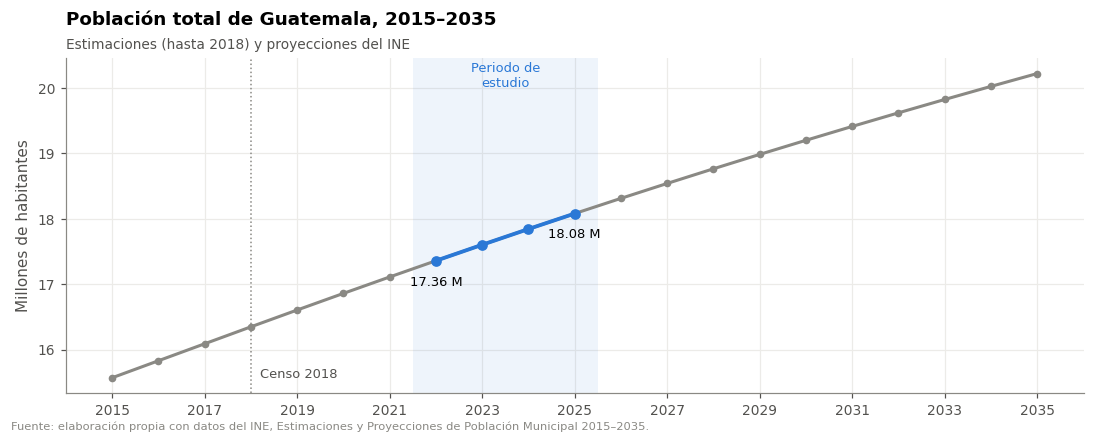

Población 2022: 17,357,886   Población 2025: 18,079,810
Crecimiento medio anual 2022–2025: 1.37%


In [9]:
serie_nac = total_nacional[anios].astype(float)

fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(2021.5, 2025.5, color=COLOR["azul"], alpha=0.08, lw=0)
ax.plot(anios, serie_nac / 1e6, color=COLOR["gris"], marker="o", markersize=4)
ax.plot(ANIOS_ESTUDIO, serie_nac[ANIOS_ESTUDIO] / 1e6, color=COLOR["azul"],
        marker="o", markersize=6, linewidth=2.5)
ax.axvline(2018, color=COLOR["gris"], linestyle=":", linewidth=1)
ax.text(2018.2, serie_nac.min() / 1e6, "Censo 2018", fontsize=8.5, color=COLOR["texto_sec"])
ax.text(2023.5, serie_nac.max() / 1e6 * 0.99, "Periodo de\nestudio", ha="center",
        fontsize=8.5, color=COLOR["azul"])
for a in [2022, 2025]:
    ax.annotate(f"{serie_nac[a] / 1e6:.2f} M", (a, serie_nac[a] / 1e6),
                textcoords="offset points", xytext=(0, -16), ha="center", fontsize=8.5)
ax.set_ylabel("Millones de habitantes")
ax.set_xticks(anios[::2])
ax.set_title("Población total de Guatemala, 2015–2035")
subtitulo(ax, "Estimaciones (hasta 2018) y proyecciones del INE")
fuente(fig, FUENTE_INE)
fig.tight_layout()
guardar_figura(fig, "01_poblacion_nacional", CARPETA_FIG)
plt.show()

crec_nac = (serie_nac[2025] / serie_nac[2022]) ** (1 / 3) - 1
print(f"Población 2022: {serie_nac[2022]:,.0f}   Población 2025: {serie_nac[2025]:,.0f}")
print(f"Crecimiento medio anual 2022–2025: {crec_nac:.2%}")

> **Nota metodológica:** las cifras 2022–2025 son **proyecciones** a partir del Censo 2018, no conteos observados. Es la fuente oficial disponible y la estándar para calcular tasas municipales en Guatemala, pero se debe mencionar como limitación.

## 4. Distribución del tamaño de los municipios

Se usa la **población promedio 2022–2025** de cada municipio, que es el denominador que se utilizará en las tasas.

,media,mediana,desv_est,CV,min,Q1,Q3,max,asimetria,curtosis
Poblacion_prom,"52,120.04","32,376.50","84,159.78",1.61,"2,698.75","18,040.38","61,666.81","1,225,163.25",9.21,114.68


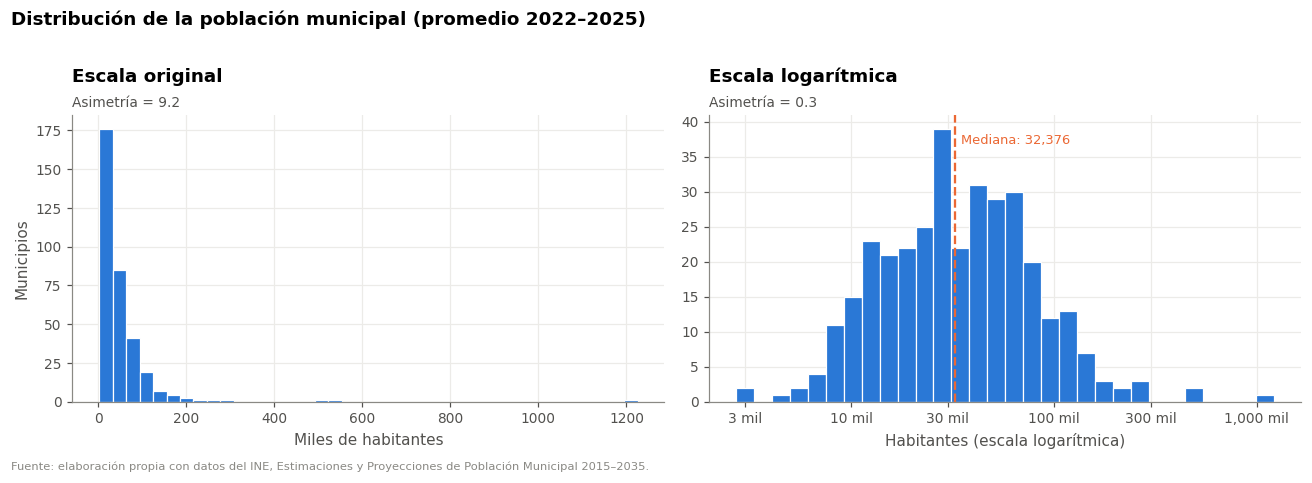

In [10]:
municipios["Poblacion_prom"] = municipios[ANIOS_ESTUDIO].mean(axis=1)
pob = municipios["Poblacion_prom"]

display(resumen_distribucion(municipios[["Poblacion_prom"]]).drop(columns="pct_ceros").round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].hist(pob / 1000, bins=40, color=COLOR["azul"], edgecolor="white", linewidth=0.8)
axes[0].set_xlabel("Miles de habitantes")
axes[0].set_ylabel("Municipios")
axes[0].set_title("Escala original")
subtitulo(axes[0], f"Asimetría = {stats.skew(pob):.1f}")

axes[1].hist(np.log10(pob), bins=30, color=COLOR["azul"], edgecolor="white", linewidth=0.8)
ticks = [3e3, 1e4, 3e4, 1e5, 3e5, 1e6]
axes[1].set_xticks(np.log10(ticks), [f"{t/1000:,.0f} mil" for t in ticks])
axes[1].axvline(np.log10(pob.median()), color=COLOR["naranja"], linewidth=1.5, linestyle="--")
axes[1].text(np.log10(pob.median()) + 0.03, axes[1].get_ylim()[1] * 0.9,
             f"Mediana: {pob.median():,.0f}", color=COLOR["naranja"], fontsize=8.5)
axes[1].set_xlabel("Habitantes (escala logarítmica)")
axes[1].set_title("Escala logarítmica")
subtitulo(axes[1], f"Asimetría = {stats.skew(np.log10(pob)):.1f}")
fig.suptitle("Distribución de la población municipal (promedio 2022–2025)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fuente(fig, FUENTE_INE)
fig.tight_layout(rect=(0, 0.02, 1, 0.97))
guardar_figura(fig, "02_distribucion_poblacion", CARPETA_FIG)
plt.show()

### 4.1 Municipios más y menos poblados

In [11]:
cols = ["Codigo_Municipio", "Departamento", "Municipio", "Poblacion_prom"]
print("Los 10 municipios más poblados")
display(municipios.nlargest(10, "Poblacion_prom")[cols].reset_index(drop=True))
print("Los 10 municipios menos poblados")
display(municipios.nsmallest(10, "Poblacion_prom")[cols].reset_index(drop=True))

Los 10 municipios más poblados


,Codigo_Municipio,Departamento,Municipio,Poblacion_prom
0,101,Guatemala,Guatemala,"1,225,163.25"
1,108,Guatemala,Mixco,"533,025.00"
2,115,Guatemala,Villa Nueva,"496,834.00"
3,110,Guatemala,San Juan Sacatepéquez,"289,584.25"
4,1609,Alta Verapaz,San Pedro Carchá,"270,169.75"
5,1601,Alta Verapaz,Cobán,"239,716.00"
6,901,Quetzaltenango,Quetzaltenango,"209,345.75"
7,2101,Jalapa,Jalapa,"196,571.75"
8,501,Escuintla,Escuintla,"173,304.75"
9,2201,Jutiapa,Jutiapa,"169,612.75"


Los 10 municipios menos poblados


,Codigo_Municipio,Departamento,Municipio,Poblacion_prom
0,703,Sololá,Santa María Visitación,"2,698.75"
1,716,Sololá,San Marcos La Laguna,"3,027.00"
2,316,Sacatepéquez,Santa Catarina Barahona,"4,789.75"
3,711,Sololá,Santa Catarina Palopó,"4,987.00"
4,702,Sololá,San José Chacayá,"5,445.75"
5,1228,San Marcos,Río Blanco,"6,272.50"
6,2208,Jutiapa,Jerez,"7,056.50"
7,1333,Huehuetenango,Petatán,"7,341.25"
8,1702,Petén,San José,"7,354.50"
9,708,Sololá,Concepción,"7,503.50"


### 4.2 Tamaño de los municipios por departamento

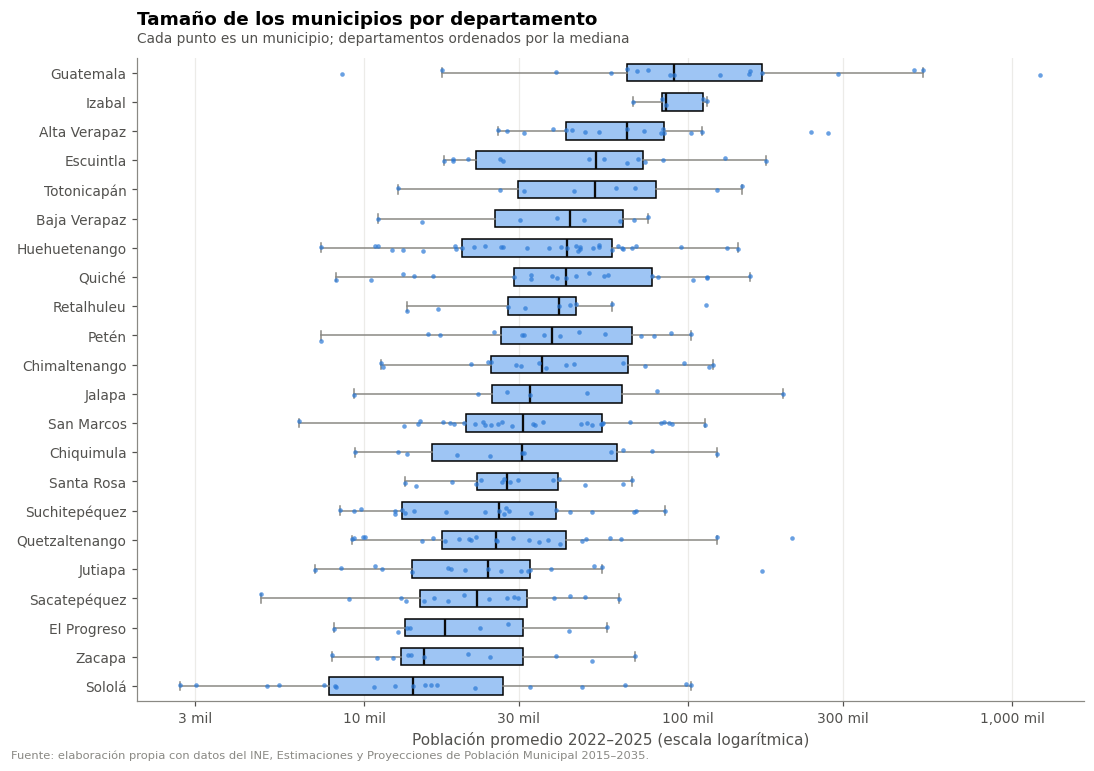

In [12]:
orden = municipios.groupby("Departamento")["Poblacion_prom"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 7))
datos_box = [np.log10(municipios.loc[municipios["Departamento"] == d, "Poblacion_prom"]) for d in orden]
bp = ax.boxplot(datos_box, vert=False, patch_artist=True, widths=0.6, showfliers=False,
                medianprops=dict(color=COLOR["texto"], linewidth=1.5),
                whiskerprops=dict(color=COLOR["gris"]), capprops=dict(color=COLOR["gris"]))
for caja in bp["boxes"]:
    caja.set_facecolor("#9ec5f4")
for i, d in enumerate(orden, start=1):
    y = np.log10(municipios.loc[municipios["Departamento"] == d, "Poblacion_prom"])
    ax.scatter(y, np.random.default_rng(i).normal(i, 0.06, len(y)), s=9,
               color=COLOR["azul"], alpha=0.7, zorder=3)
ax.set_yticks(range(1, len(orden) + 1), orden)
ticks = [3e3, 1e4, 3e4, 1e5, 3e5, 1e6]
ax.set_xticks(np.log10(ticks), [f"{t/1000:,.0f} mil" for t in ticks])
ax.set_xlabel("Población promedio 2022–2025 (escala logarítmica)")
ax.grid(axis="y", visible=False)
ax.set_title("Tamaño de los municipios por departamento")
subtitulo(ax, "Cada punto es un municipio; departamentos ordenados por la mediana")
fuente(fig, FUENTE_INE)
fig.tight_layout()
guardar_figura(fig, "03_poblacion_por_departamento", CARPETA_FIG)
plt.show()

## 5. Crecimiento 2022–2025

Se calcula la **tasa de crecimiento media anual** de cada municipio: $r = \left(\frac{P_{2025}}{P_{2022}}\right)^{1/3} - 1$.

,Crecimiento anual (%)
count,340.00
mean,1.36
std,0.50
min,0.08
25%,1.06
50%,1.36
75%,1.69
max,2.62


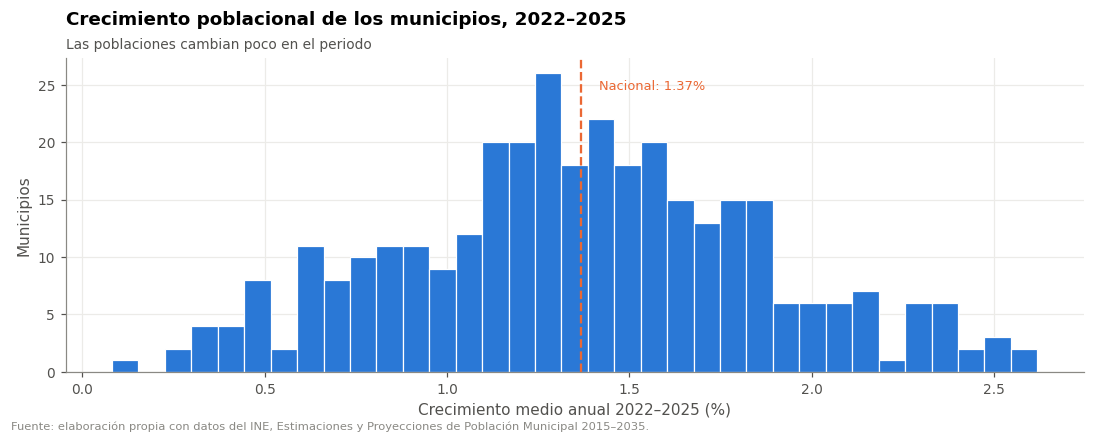

Cambio total 2022–2025: mínimo 0.2 %, mediana 4.1 %, máximo 8.1 %


In [13]:
municipios["Crec_anual_pct"] = ((municipios[2025] / municipios[2022]) ** (1 / 3) - 1) * 100
display(municipios["Crec_anual_pct"].describe().to_frame("Crecimiento anual (%)"))

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(municipios["Crec_anual_pct"], bins=35, color=COLOR["azul"], edgecolor="white", linewidth=0.8)
ax.axvline(crec_nac * 100, color=COLOR["naranja"], linestyle="--", linewidth=1.5)
ax.text(crec_nac * 100 + 0.05, ax.get_ylim()[1] * 0.9, f"Nacional: {crec_nac:.2%}",
        color=COLOR["naranja"], fontsize=8.5)
ax.set_xlabel("Crecimiento medio anual 2022–2025 (%)")
ax.set_ylabel("Municipios")
ax.set_title("Crecimiento poblacional de los municipios, 2022–2025")
subtitulo(ax, "Las poblaciones cambian poco en el periodo")
fuente(fig, FUENTE_INE)
fig.tight_layout()
guardar_figura(fig, "04_crecimiento_poblacional", CARPETA_FIG)
plt.show()

cambio_total = (municipios[2025] / municipios[2022] - 1) * 100
print(f"Cambio total 2022–2025: mínimo {cambio_total.min():.1f} %, "
      f"mediana {cambio_total.median():.1f} %, máximo {cambio_total.max():.1f} %")

Como la población cambia poco entre 2022 y 2025, usar la **población de cada año** o la **población promedio** produce tasas prácticamente iguales. Esto da flexibilidad en la construcción de indicadores.

## 6. Concentración de la población

Índice de Gini de la población municipal: 0.497
Los 10 municipios más poblados concentran el 21.5 % de la población


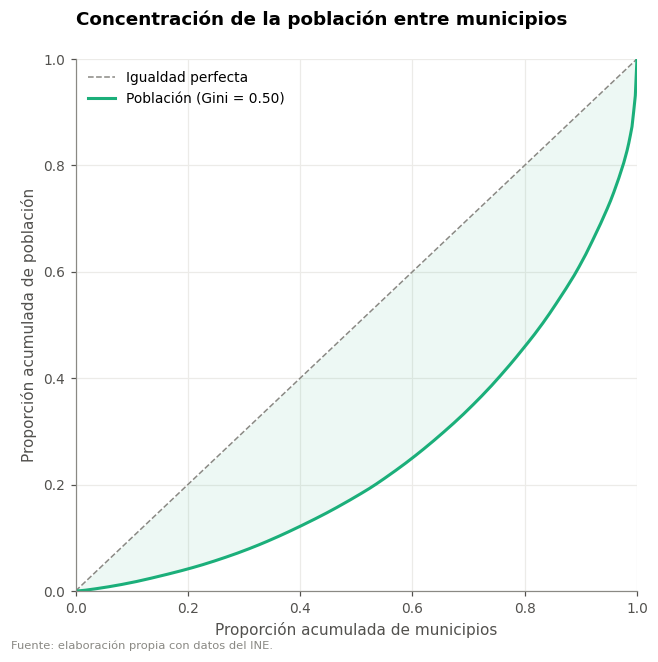

In [14]:
gini_pob = coeficiente_gini(pob)
x_l, y_l = curva_lorenz(pob)
top10 = pob.nlargest(10).sum() / pob.sum() * 100
print(f"Índice de Gini de la población municipal: {gini_pob:.3f}")
print(f"Los 10 municipios más poblados concentran el {top10:.1f} % de la población")

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], color=COLOR["gris"], linestyle="--", linewidth=1, label="Igualdad perfecta")
ax.plot(x_l, y_l, color=COLOR["aqua"], label=f"Población (Gini = {gini_pob:.2f})")
ax.fill_between(x_l, y_l, x_l, color=COLOR["aqua"], alpha=0.08)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Proporción acumulada de municipios")
ax.set_ylabel("Proporción acumulada de población")
ax.set_title("Concentración de la población entre municipios")
ax.legend(loc="upper left")
fuente(fig, "Fuente: elaboración propia con datos del INE.")
fig.tight_layout()
guardar_figura(fig, "05_lorenz_poblacion", CARPETA_FIG)
plt.show()

La población está concentrada, pero bastante **menos que las denuncias** (Gini de denuncias = 0.77 en el notebook 01). Esa diferencia es una primera señal de que la incidencia delictiva **no es proporcional** a la población: algunos municipios denuncian mucho más de lo que su tamaño explicaría.

## 7. Municipios pequeños y estabilidad de las tasas

Una tasa por 100,000 habitantes en un municipio de 5,000 personas convierte **una sola denuncia** en 20 puntos de tasa. Por eso las tasas de los municipios pequeños son más **volátiles**, sobre todo en los delitos poco frecuentes. Se cuantifica cuántos municipios están en esta situación.

,Municipios,% de municipios,Población de referencia,Tasa que aporta 1 denuncia (por 100 mil)
Rango_poblacion,,,,
< 10 mil,26,7.65,5000,20.00
10–20 mil,71,20.88,10000,10.00
20–50 mil,132,38.82,20000,5.00
50–100 mil,76,22.35,50000,2.00
100–500 mil,33,9.71,100000,1.00
> 500 mil,2,0.59,500000,0.20


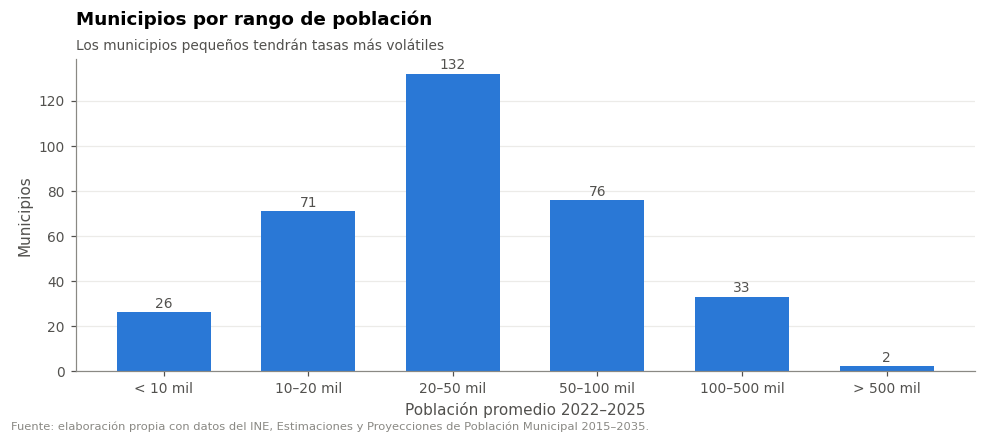

In [15]:
cortes = [0, 10_000, 20_000, 50_000, 100_000, 500_000, np.inf]
etiquetas = ["< 10 mil", "10–20 mil", "20–50 mil", "50–100 mil", "100–500 mil", "> 500 mil"]
municipios["Rango_poblacion"] = pd.cut(pob, bins=cortes, labels=etiquetas, right=False)
rangos = municipios["Rango_poblacion"].value_counts().reindex(etiquetas)
referencia = [5_000, 10_000, 20_000, 50_000, 100_000, 500_000]
tabla_rangos = pd.DataFrame({
    "Municipios": rangos,
    "% de municipios": rangos / rangos.sum() * 100,
    "Población de referencia": referencia,
    "Tasa que aporta 1 denuncia (por 100 mil)": [100_000 / r for r in referencia],
})
display(tabla_rangos)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(etiquetas, rangos.values, color=COLOR["azul"], width=0.65)
for i, v in enumerate(rangos.values):
    ax.text(i, v + 2, f"{v}", ha="center", fontsize=9, color=COLOR["texto_sec"])
ax.grid(axis="x", visible=False)
ax.set_ylabel("Municipios")
ax.set_xlabel("Población promedio 2022–2025")
ax.set_title("Municipios por rango de población")
subtitulo(ax, "Los municipios pequeños tendrán tasas más volátiles")
fuente(fig, FUENTE_INE)
fig.tight_layout()
guardar_figura(fig, "06_municipios_por_rango", CARPETA_FIG)
plt.show()

Lectura de la tabla: en un municipio de 5,000 habitantes, **una sola denuncia** equivale a una tasa de 20 por 100 mil; en uno de 500,000, apenas a 0.2. Casi **3 de cada 10 municipios** tienen menos de 20 mil habitantes.

## 8. Exportación

Se guardan dos tablas:

- `poblacion_municipal_2015_2035.csv`: formato largo (*municipio × año*) con el código INE.
- La población promedio 2022–2025 se recalcula en el notebook 03 a partir de esta tabla.

In [16]:
pob_larga = municipios.melt(
    id_vars=["Codigo_Municipio", "Codigo_Depto", "Departamento", "Municipio"],
    value_vars=anios, var_name="Anio", value_name="Poblacion")
pob_larga["Anio"] = pob_larga["Anio"].astype(int)
pob_larga["Poblacion"] = pob_larga["Poblacion"].round().astype("Int64")  # admite los 2 sin dato de 2015
pob_larga = pob_larga.sort_values(["Codigo_Municipio", "Anio"]).reset_index(drop=True)

ruta_salida = RUTA_PROCESSED / "poblacion_municipal_2015_2035.csv"
pob_larga.to_csv(ruta_salida, index=False, encoding="utf-8-sig")
assert len(pob_larga) == 340 * len(anios)
print(f"Guardado: {ruta_salida.relative_to(RAIZ)}  ({len(pob_larga):,} filas)")

Guardado: data\processed\poblacion_municipal_2015_2035.csv  (7,140 filas)


## 9. Conclusiones

**Calidad de los datos**

- El archivo del INE se estructuró correctamente: **22 departamentos y 340 municipios**, sin duplicados y con el **código geográfico INE** como llave.
- Es **internamente consistente**: los municipios suman exactamente el total de su departamento, y los departamentos el total nacional, en todos los años.
- Solo faltan los datos de 2015 de **Sipacate** y **Petatán**, municipios creados ese año. El periodo 2022–2025 está **completo**.

**Distribución**

- El tamaño de los municipios es muy desigual: mediana de **32 mil** habitantes, desde 2.7 mil (Santa María Visitación) hasta 1.2 millones (Guatemala). La distribución es muy asimétrica (9.2), pero en **escala logarítmica es casi simétrica** (0.3).
- La población crece de forma moderada y homogénea (**1.4 % anual**; entre 0.2 % y 8.1 % acumulado de 2022 a 2025). Por eso da prácticamente igual usar la población de cada año o su promedio.
- La población está concentrada (Gini **0.50**), pero mucho menos que las denuncias (Gini **0.77**). Esto indica que la incidencia delictiva **no es simplemente proporcional** al tamaño del municipio.

**Implicaciones**

1. La población es un denominador **confiable y completo** para calcular tasas.
2. Hay **97 municipios con menos de 20 mil habitantes** (28.5 %). En ellos, pocas denuncias producen tasas altas y volátiles, sobre todo en los delitos poco frecuentes. Esto se evalúa en el notebook 03 y puede requerir tratamiento en el preprocesamiento (por ejemplo, agregar los 4 años o suavizar las tasas).
3. Se conserva el **código INE** para unir los resultados con la capa geográfica del mapa coroplético.